In [61]:
# importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns # visualition
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import pickle # elle permet deployer le modele

In [62]:
#lire la base de données
df=pd.read_csv('data/train_u6lujuX_CVtuZ9i.csv')
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [63]:

#pd.set_option('display.max_rows',df.shape[0]+1) Elle permet de lire toute la base de donnnées
pd.set_option('display.max_rows',10) #Elle permet de lire 10 lignes

In [64]:
# on va le nombre des colonnes et nombre de valeurs maquanntes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [65]:
# On veut savoir le nombre de valeurs manquantes
df.isnull().sum().sort_values(ascending = False)

Credit_History       50
Self_Employed        32
LoanAmount           22
Dependents           15
Loan_Amount_Term     14
                     ..
Education             0
ApplicantIncome       0
CoapplicantIncome     0
Property_Area         0
Loan_Status           0
Length: 13, dtype: int64

In [66]:
# On veut connaitre les nombre de valeurs mal renseigné

df.describe()  # 

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


count = 614 valeur de manquant 	ApplicantIncome	, 614.000000 valeur de 	CoapplicantIncome 614.000000

Nb si min est une valeur negatif alors il y a un problème

In [67]:
#variable categorique


df.describe(include="O")

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP001002,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


Une valeur catégorielle est une valeur qui représente une catégorie, et non une quantité numérique.

| Personne | Âge | Genre | Contrat |
| -------- | --: | ----- | ------- |
| A        |  25 | Homme | CDI     |
| B        |  32 | Femme | CDD     |
| C        |  41 | Homme | CDI     |
En Machine Learning

Les modèles comme RandomForest, SVM, LogisticRegression, etc. travaillent généralement avec des nombres. Il faut donc transformer les catégories en nombres.
Valeur catégorielle = une valeur qui indique à quelle catégorie appartient une observation.

Exemples : Homme/Femme, CDI/CDD, Paris/Lyon/Marseille, Oui/Non, Rouge/Bleu/Vert.

Si tu veux, je peux aussi t'expliquer la différence entre variable catégorielle nominale et ordinale, qui est très importante en Machine Learning.

In [68]:
# Renseigner les valeurs manquantes  ,on va travailler avec les valeurs manquante numerique 
cat_data=[]
num_data=[]
for i,c in enumerate(df.dtypes):
  if c==object:
    cat_data.append(df.iloc[:,i])
  else:
    num_data.append(df.iloc[:,i])
cat_data=pd.DataFrame(cat_data).transpose()
num_data=pd.DataFrame(num_data).transpose()

cat_data = pd.DataFrame(cat_data)
cat_data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,Urban,Y
4,LP001008,Male,No,0,Graduate,No,Urban,Y
...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,Urban,Y


In [69]:
# Pour les variables catégoriques on va remplaczr les valeurs manquantes par les valeurs qui se repetent le plus
cat_data=cat_data.apply(lambda x:x.fillna(x.value_counts().index[0]))
cat_data.isnull().sum().any()




False

In [70]:
# Pour les variables numériques on va remplacer les valeurs manquantes par la valeur précedente de la meme colonne
num_data.fillna(method='bfill',inplace=True)
num_data.isnull().sum().any()

C:\Users\besse\AppData\Local\Temp\ipykernel_29628\3829356050.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  num_data.fillna(method='bfill',inplace=True)


False

In [71]:
# Tranformer la colonne target  , On veut transformer Y = 1 et N =0
target_value={'Y':1,'N':0}
target=cat_data['Loan_Status']
cat_data.drop('Loan_Status',axis=1,inplace=True)
target=target.map(target_value)
target

0      1
1      0
2      1
3      1
4      1
      ..
609    1
610    1
611    1
612    1
613    0
Name: Loan_Status, Length: 614, dtype: int64

In [72]:
# Remplacer les valeurs catégoriques par des valeurs numérique 0,1,2..., 
le=LabelEncoder()
for i in cat_data:
  cat_data[i]=le.fit_transform(cat_data[i])
cat_data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area
0,0,1,0,0,0,0,2
1,1,1,1,1,0,0,0
2,2,1,1,0,0,1,2
3,3,1,1,0,1,0,2
4,4,1,0,0,0,0,2
...,...,...,...,...,...,...,...
609,609,0,0,0,0,0,0
610,610,1,1,3,0,0,0
611,611,1,1,1,0,0,2
612,612,1,1,2,0,0,2


LabelEncoder() sert à transformer des catégories en nombres pour qu'un modèle de Machine Learning puisse les utiliser.  Dans colonne Married {1 = Marié,0 = pas Marié } etc...

In [73]:
# Supprimer loan_id, elle n est pas utile
cat_data.drop('Loan_ID',axis=1,inplace=True)

cat_data

,Gender,Married,Dependents,Education,Self_Employed,Property_Area
0,1,0,0,0,0,2
1,1,1,1,0,0,0
2,1,1,0,0,1,2
3,1,1,0,1,0,2
4,1,0,0,0,0,2
...,...,...,...,...,...,...
609,0,0,0,0,0,0
610,1,1,3,0,0,0
611,1,1,1,0,0,2
612,1,1,2,0,0,2


In [74]:
# Concatener cat_Data et num_data et spécifier la colonne target
X=pd.concat([cat_data,num_data],axis=1)
y=target

Réaliser une Analyse Exploratoire (EDA)

In [75]:
# va commencer par la variable target (variable cible) 1 = credit accepté et 0 = refusé
target.value_counts()

Loan_Status
1    422
0    192
Name: count, dtype: int64

ON va visulisé nos données

In [76]:
# la base de données utilisée pour EDA

df=pd.concat([cat_data,num_data,target],axis=1)

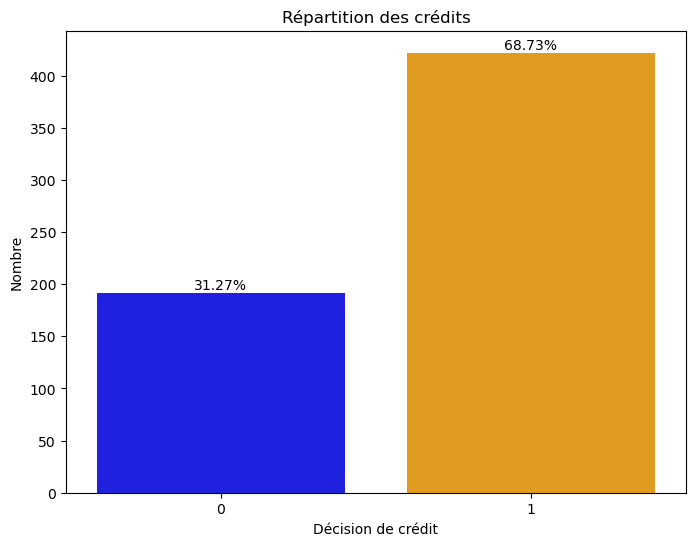

Nombre de crédits par catégorie :
Loan_Status
1    422
0    192
Name: count, dtype: int64

Pourcentage de chaque catégorie :
Loan_Status
1    68.729642
0    31.270358
Name: proportion, dtype: float64

Le pourcentage des crédits accordés est : 31.27%
Le pourcentage des crédits non accordés est : 68.73%


In [77]:


# ==========================================
# Graphique
# ==========================================

plt.figure(figsize=(8, 6))

ax = sns.countplot(
    x=target,
    hue=target,
    palette={0: "blue", 1: "orange"},
    legend=False
)

plt.title("Répartition des crédits")
plt.xlabel("Décision de crédit")
plt.ylabel("Nombre")

# ==========================================
# Ajouter les pourcentages sur les barres
# ==========================================

total = len(target)

for bar in ax.patches:
    hauteur = bar.get_height()
    pourcentage = (hauteur / total) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        hauteur,
        f"{pourcentage:.2f}%",
        ha="center",
        va="bottom"
    )

plt.show()


# ==========================================
# Nombre de crédits
# ==========================================

print("Nombre de crédits par catégorie :")
print(target.value_counts())


# ==========================================
# Pourcentages
# ==========================================

pourcentages = target.value_counts(normalize=True) * 100

print("\nPourcentage de chaque catégorie :")
print(pourcentages)


# ==========================================
# 0 = crédit accordé
# 1 = crédit non accordé
# ==========================================

yes = (target.value_counts()[0] / len(target)) * 100
no = (target.value_counts()[1] / len(target)) * 100

print(f"\nLe pourcentage des crédits accordés est : {yes:.2f}%")
print(f"Le pourcentage des crédits non accordés est : {no:.2f}%")

c:\Users\besse\anaconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


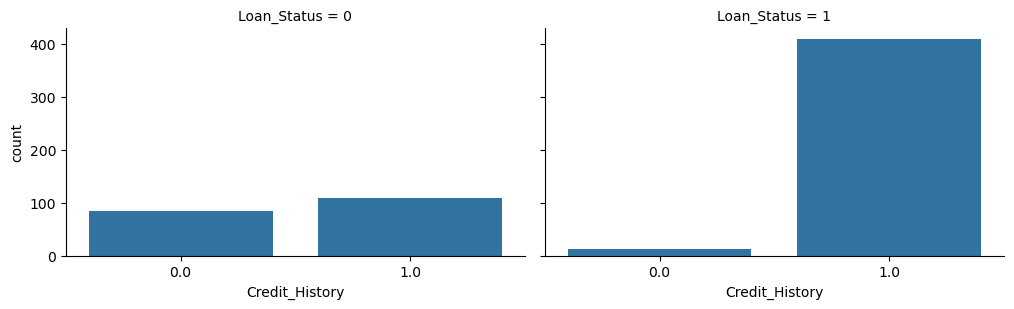

In [78]:
# Credit History

grid = sns.FacetGrid(
    df,
    col='Loan_Status',
    height=3.2,
    aspect=1.6
)

grid.map(sns.countplot, 'Credit_History')

plt.show()

Loan_status=0 est pour les personnes qui n ont jamais eu de crédit et le graphe montre les personnes  qui ont le credit ou pas.

Loan_status=1 est pour les personnes qui ont deja eu un crédit et le graphe montre les personnes  qui ont le credit ou pas

c:\Users\besse\anaconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


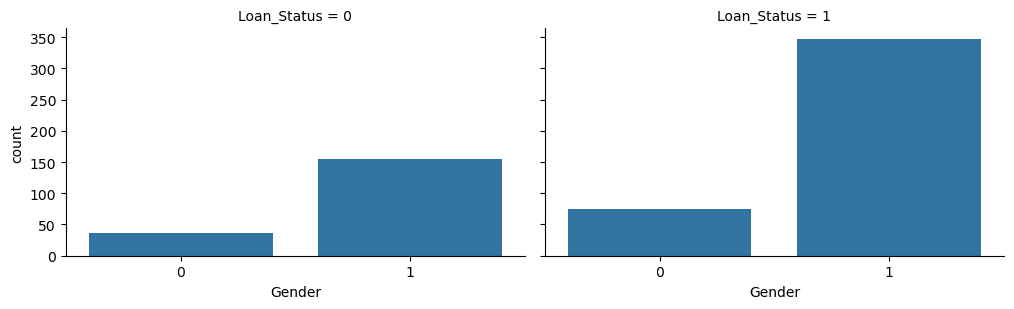

In [79]:
# Sexe
grid=sns.FacetGrid(df,
   col='Loan_Status', 
    height=3.2,
    aspect=1.6)
grid.map(sns.countplot,'Gender')

**Loan_Status = 0 : personnes qui n'ont jamais eu de crédit**
Le graphe montre environ 192 personnes : ~37 femmes (0) et ~155 hommes (1).
Les hommes sont majoritaires dans ce groupe.

**Loan_Status = 1 : personnes qui ont déjà eu un crédit**
Le graphe montre environ 422 personnes : ~75 femmes (0) et ~347 hommes (1).
Les hommes sont aussi majoritaires dans ce groupe.

**Conclusion**
Environ 67 % des femmes et 69 % des hommes ont déjà eu un crédit.
La proportion est presque la même pour les deux sexes, donc le genre
n'a pratiquement pas d'influence.

c:\Users\besse\anaconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


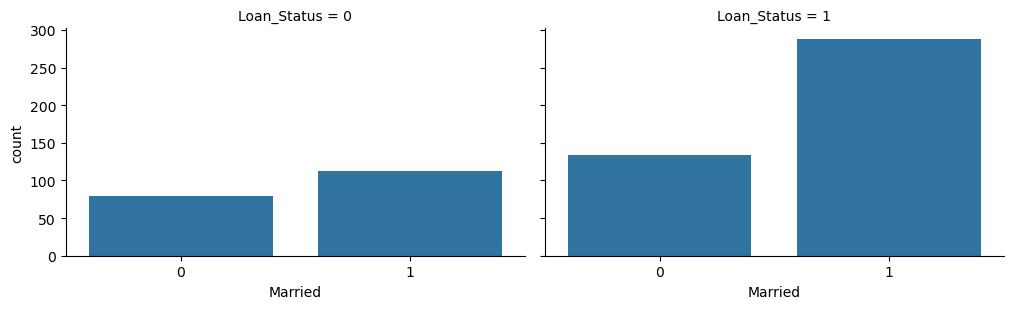

In [80]:
# Sexe
grid=sns.FacetGrid(df,col='Loan_Status',height=3.2,  aspect=1.6)         
grid.map(sns.countplot,'Married')

c:\Users\besse\anaconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


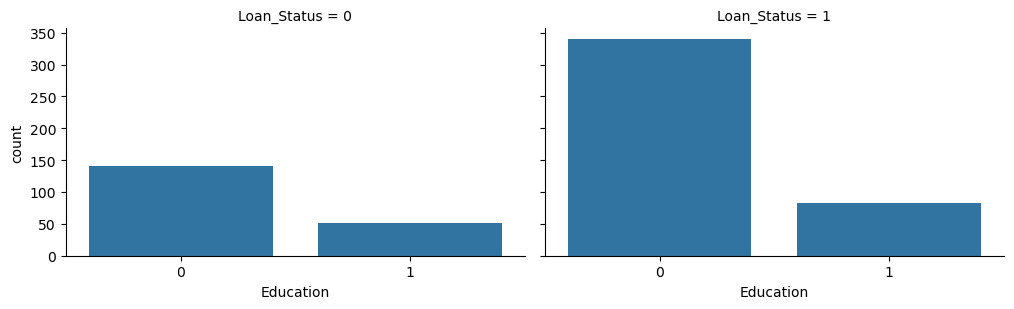

In [81]:
# Education
grid=sns.FacetGrid(df,col='Loan_Status',height=3.2,aspect=1.6)
grid.map(sns.countplot,'Education')

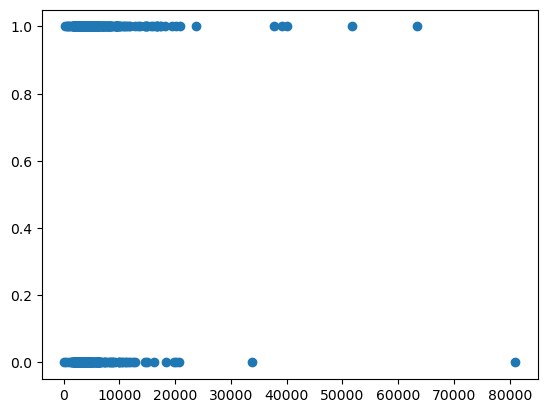

In [82]:
# revenu du demandeur
plt.scatter(df['ApplicantIncome'],df['Loan_Status'])

# 0 axe des ordonnée represente credut accèpté et 0 credit pas accèpté



In [83]:
df.groupby('Loan_Status').median()

,Gender,Married,Dependents,Education,Self_Employed,Property_Area,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
Loan_Status,,,,,,,,,,,
0,1.0,1.0,0.0,0.0,0.0,1.0,3833.5,268.0,132.5,360.0,1.0
1,1.0,1.0,0.0,0.0,0.0,1.0,3812.5,1239.5,127.5,360.0,1.0


StratifiedShuffleSplit sert à séparer les données en entraînement et test en gardant la même proportion de 0 et de 1 dans les deux.

C'est utile car Loan_Status est déséquilibré (environ 69 % de 1 et 31 % de 0). Un découpage au hasard pourrait donner un test mal représentatif et fausser l'évaluation du modèle. Avec la stratification, le train et le test gardent tous les deux environ 69 % / 31 %. ON utilse StratifiedShuffleSplit parce qu il y a desiquilibre

In [84]:
# Diviser la base de données en une base de données test et d'entrainement
# ON utilse StratifiedShuffleSplit parce qu il y a desiquilibre
sss=StratifiedShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
for train,test in sss.split(X,y):
  X_train,X_test=X.iloc[train],X.iloc[test]
  y_train,y_test=y.iloc[train],y.iloc[test]

print('X_train taille: ', X_train.shape)
print('X_test taille: ', X_test.shape)
print('y_train taille: ', y_train.shape)
print('y_test taille: ', y_test.shape)

X_train taille:  (491, 11)
X_test taille:  (123, 11)
y_train taille:  (491,)
y_test taille:  (123,)


In [85]:
# On va appliquer tois algorithmes Logisitic Regression, KNN, DecisionTree
models={
    'LogisticRegression':LogisticRegression(random_state=42),
    'KNeighborsClassifier':KNeighborsClassifier(),
    'DecisionTreeClassifier':DecisionTreeClassifier(max_depth=1,random_state=42)
}

# La fonction de précision
def accu(y_true,y_pred,retu=False):
  acc=accuracy_score(y_true,y_pred)
  if retu:
    return acc
  else:
    print(f'la precision du modèle est: {acc}')

#c'est la fonction d'application des modèles
def train_test_eval(models,X_train,y_train,X_test,y_test):
  for name,model in models.items():
    print(name,':')
    model.fit(X_train,y_train)
    accu(y_test,model.predict(X_test))
    print('-'*30)

train_test_eval(models,X_train,y_train,X_test,y_test)

LogisticRegression :
la precision du modèle est: 0.8536585365853658
------------------------------
KNeighborsClassifier :
la precision du modèle est: 0.6504065040650406
------------------------------
DecisionTreeClassifier :
la precision du modèle est: 0.8455284552845529
------------------------------


c:\Users\besse\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [86]:
# On va teste les données avec des données
X_2=X[['Credit_History','Married','CoapplicantIncome']]

In [87]:
# Diviser la base de données en une base de données test et d'entrainement
sss=StratifiedShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
for train,test in sss.split(X_2,y):
  X_train,X_test=X_2.iloc[train],X_2.iloc[test]
  y_train,y_test=y.iloc[train],y.iloc[test]

print('X_train taille: ', X_train.shape)
print('X_test taille: ', X_test.shape)
print('y_train taille: ', y_train.shape)
print('y_test taille: ', y_test.shape)

X_train taille:  (491, 3)
X_test taille:  (123, 3)
y_train taille:  (491,)
y_test taille:  (123,)


In [88]:
train_test_eval(models,X_train,y_train,X_test,y_test)

LogisticRegression :
la precision du modèle est: 0.8536585365853658
------------------------------
KNeighborsClassifier :
la precision du modèle est: 0.6991869918699187
------------------------------
DecisionTreeClassifier :
la precision du modèle est: 0.8455284552845529
------------------------------


In [89]:
# Appliquer la regression logisitique sur notre base de donnée
Classifier=LogisticRegression()
Classifier.fit(X_2,y)

LogisticRegression()

In [90]:
# Enregistrer le modèle
pickle.dump(Classifier,open('model.pkl','wb'))